In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             roc_curve, auc, confusion_matrix, classification_report)
from sklearn.preprocessing import label_binarize

In [ ]:
df = pd.read_csv('loan_data.csv')   # adjust filename if needed
print("Original dataset shape:", df.shape)

Original dataset shape: (45000, 14)


In [ ]:
df.drop(['loan_int_rate', 'loan_percent_income'], axis=1, inplace=True)
print("Columns after dropping:", df.columns.tolist())

Columns after dropping: ['person_age', 'person_gender', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'loan_status']


In [ ]:
target = 'loan_intent'
predictors = ['person_gender', 'person_age', 'person_education', 'person_income']

In [ ]:
df_clean = df[predictors + [target]].copy()
df_clean.dropna(inplace=True)
print(f"Rows after dropping missing values: {df_clean.shape[0]}")

Rows after dropping missing values: 45000


In [ ]:
print("\n--- Clean dataset (first 5 rows) ---")
print(df_clean.head())


--- Clean dataset (first 5 rows) ---
  person_gender  person_age person_education  person_income loan_intent
0        female          22           Master          71948    PERSONAL
1        female          21      High School          12282   EDUCATION
2        female          25      High School          12438     MEDICAL
3        female          23         Bachelor          79753     MEDICAL
4          male          24           Master          66135     MEDICAL


In [ ]:
le_gender = LabelEncoder()
le_education = LabelEncoder()
le_target = LabelEncoder()

df_clean['person_gender_enc'] = le_gender.fit_transform(df_clean['person_gender'])
df_clean['person_education_enc'] = le_education.fit_transform(df_clean['person_education'])
df_clean['loan_intent_enc'] = le_target.fit_transform(df_clean[target])

In [ ]:
X = df_clean[['person_age', 'person_income', 'person_gender_enc', 'person_education_enc']]
y = df_clean['loan_intent_enc']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
print(f"\nTraining set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")


Training set size: 36000
Testing set size: 9000


In [ ]:
clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)   # probabilities for ROC curves

In [ ]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {accuracy:.4f}")


Accuracy: 0.2311


In [ ]:
recall = recall_score(y_test, y_pred, average='macro')
print(f"Recall (macro): {recall:.4f}")

Recall (macro): 0.2031


In [ ]:
precision = precision_score(y_test, y_pred, average='macro')
print(f"Precision (macro): {precision:.4f}")

Precision (macro): 0.2809


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Classification report (per class)
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=le_target.classes_))


--- Classification Report ---
                   precision    recall  f1-score   support

DEBTCONSOLIDATION       0.50      0.00      0.00      1429
        EDUCATION       0.30      0.34      0.32      1831
  HOMEIMPROVEMENT       0.00      0.00      0.00       956
          MEDICAL       0.22      0.58      0.32      1710
         PERSONAL       0.48      0.02      0.03      1510
          VENTURE       0.19      0.28      0.22      1564

         accuracy                           0.23      9000
        macro avg       0.28      0.20      0.15      9000
     weighted avg       0.29      0.23      0.17      9000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


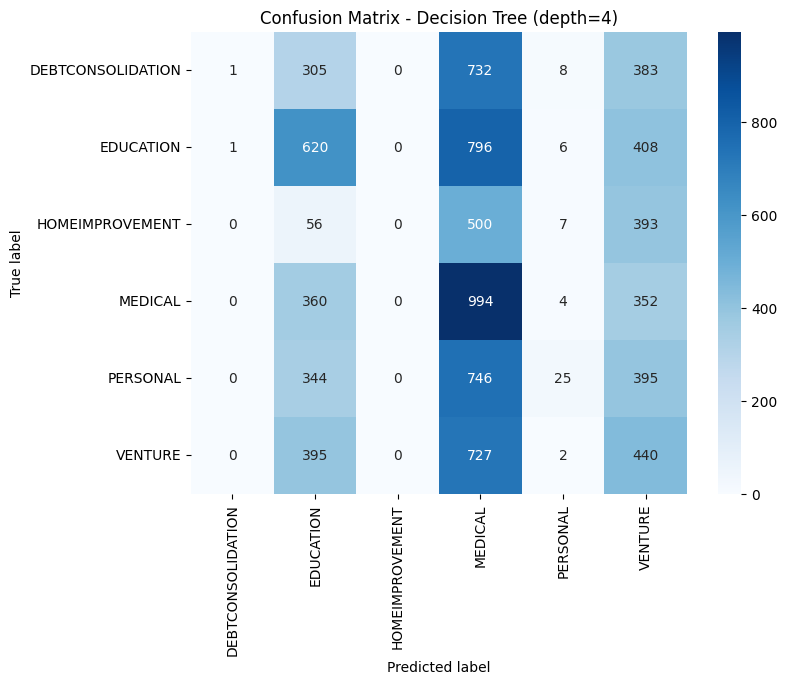

In [ ]:
# Confusion Matrix as heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_target.classes_,
            yticklabels=le_target.classes_)
plt.title('Confusion Matrix - Decision Tree (depth=4)')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

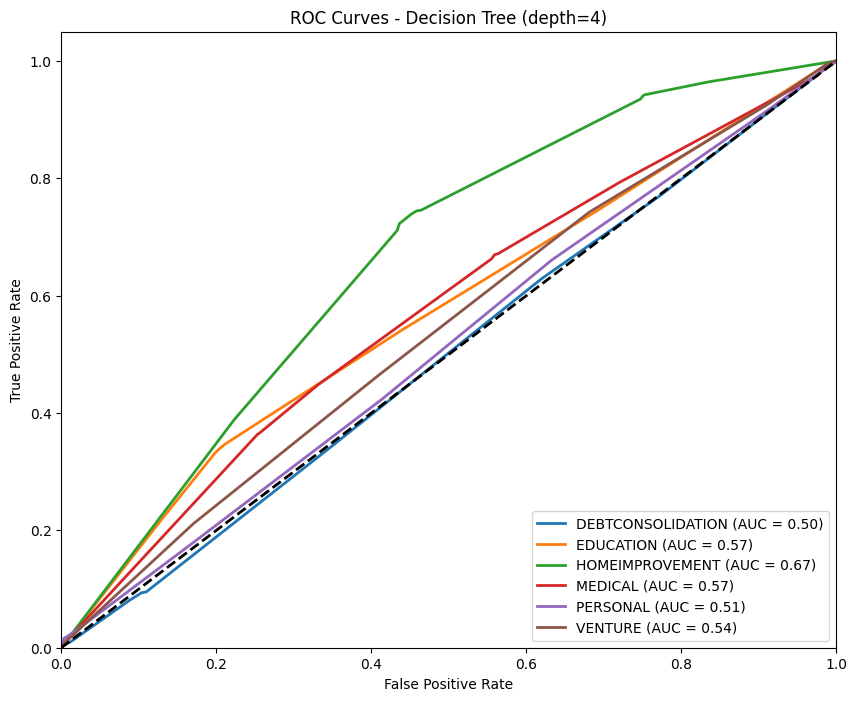

In [ ]:
# ROC Curves (One-vs-Rest) for multi-class
y_test_bin = label_binarize(y_test, classes=np.unique(y))
n_classes = y_test_bin.shape[1]

plt.figure(figsize=(10,8))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{le_target.classes_[i]} (AUC = {roc_auc:.2f})')

plt.plot([0,1],[0,1], 'k--', lw=2)
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Decision Tree (depth=4)')
plt.legend(loc="lower right")
plt.show()

In [ ]:
# K-fold cross validation (5 folds, stratified)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(clf, X, y, cv=cv, scoring='accuracy')
print(f"\nK-fold Cross-Validation (5 folds) accuracy scores: {cv_scores}")
print(f"Mean CV accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")


K-fold Cross-Validation (5 folds) accuracy scores: [0.21755556 0.23544444 0.22822222 0.23411111 0.22877778]
Mean CV accuracy: 0.2288 (+/- 0.0126)
